# gpOptimizer Multi-Task Test
At first we have to install the newest version of gpCAM

In [1]:
## First, install the newest version of gpcam and some plotting tools
#!pip install gpcam~=8.7.0
#!pip install matplotlib
#!pip install plotly
#pip install --upgrade kaleido

## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gpcam import GPOptimizer
from distributed import Client
client = Client()
import plotly.graph_objects as go
from itertools import product
import plotly.io as pio
pio.renderers.default = "png"
%load_ext autoreload
%autoreload 2

## Simple 1d Example

### Data

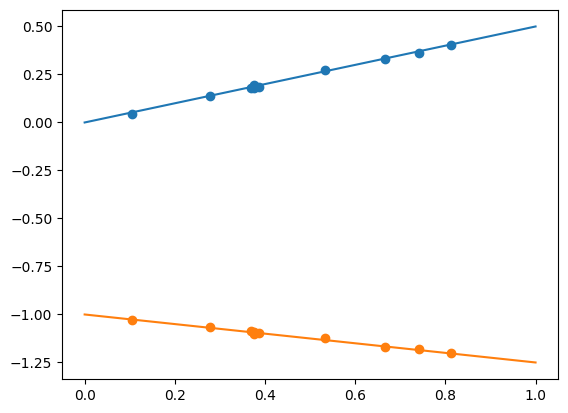

In [3]:
def f1(x): return 0.5 * x
def f2(x): return (-.25 * x) - 1.

x_pred1d = np.linspace(0,1,50)
plt.plot(x_pred1d,f1(x_pred1d))
plt.plot(x_pred1d,f2(x_pred1d))
x_data = np.random.rand(10)
y_data1 = f1(x_data) + np.random.uniform(low = -0.01, high = 0.01, size =len(x_data))
y_data2 = f2(x_data) + np.random.uniform(low = -0.01, high = 0.01, size =len(x_data))
plt.scatter(x_data,y_data1) 
plt.scatter(x_data,y_data2) 
plt.show()

### GP initialization

In [4]:
my_gp2 = GPOptimizer(x_data.reshape(len(x_data),1), np.column_stack([y_data1, y_data2]), multi_task_mode = "cartesian")
print("Local training in progress")
my_gp2.train(max_iter = 20, info=True)

Local training in progress
fvGP local optimization, start 1 of 5
fvGP local iteration 1: f(x)= -48.16204606480726
fvGP local iteration 2: f(x)= -49.342457569567046
fvGP local iteration 3: f(x)= -49.952535290877734
fvGP local iteration 4: f(x)= -50.13981763827235
fvGP local iteration 5: f(x)= -50.60028983930178
fvGP local iteration 6: f(x)= -50.791928109259615
fvGP local iteration 7: f(x)= -50.811721928831915
fvGP local iteration 8: f(x)= -50.812320337420644
fvGP local optimization, start 2 of 5
fvGP local iteration 1: f(x)= -50.717138612049226
fvGP local iteration 2: f(x)= -50.752588822204544
fvGP local iteration 3: f(x)= -50.75330167999731
fvGP local optimization, start 3 of 5
fvGP local iteration 1: f(x)= -49.482991834844626
fvGP local iteration 2: f(x)= -50.09955089399037
fvGP local iteration 3: f(x)= -50.590684201891506
fvGP local iteration 4: f(x)= -50.60842953814364
fvGP local iteration 5: f(x)= -50.60894093635304
fvGP local optimization, start 4 of 5
fvGP local iteration 1: f(x)

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:730: UserWarning:

Hyperparameters initialized to a vector of ones.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:766: UserWarning:

No noise function or measurement noise provided. Noise variances will be set to (0.01 * mean(|y_data|))^2.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1350: UserWarning:

Default hyperparameter_bounds initialized because none were provided. This will fail for custom kernel, mean, or noise functions



array([0.51987933, 5.51535087, 0.05506245])

In [5]:
print("The GP stores the data as (input, task) points, the task index in the last column:")
print(my_gp2.x_data)
print(my_gp2.y_data)

The GP stores the data as (input, task) points, the task index in the last column:
[[0.3762341  0.        ]
 [0.81304287 0.        ]
 [0.37457469 0.        ]
 [0.74088838 0.        ]
 [0.10441543 0.        ]
 [0.36868248 0.        ]
 [0.38730682 0.        ]
 [0.2777469  0.        ]
 [0.6657226  0.        ]
 [0.53343311 0.        ]
 [0.3762341  1.        ]
 [0.81304287 1.        ]
 [0.37457469 1.        ]
 [0.74088838 1.        ]
 [0.10441543 1.        ]
 [0.36868248 1.        ]
 [0.38730682 1.        ]
 [0.2777469  1.        ]
 [0.6657226  1.        ]
 [0.53343311 1.        ]]
[[ 0.17828635]
 [ 0.40309279]
 [ 0.19708578]
 [ 0.36169554]
 [ 0.04258357]
 [ 0.17960077]
 [ 0.18732514]
 [ 0.13845416]
 [ 0.32874648]
 [ 0.27400325]
 [-1.09366129]
 [-1.19886132]
 [-1.09912696]
 [-1.17792116]
 [-1.02831951]
 [-1.08721174]
 [-1.09634928]
 [-1.06536067]
 [-1.17026128]
 [-1.12371847]]


### Predictions

In [6]:
y_test = np.hstack([f1(x_pred1d).reshape(len(x_pred1d),1),f2(x_pred1d).reshape(len(x_pred1d),1)])
print("RMSE:              ", my_gp2.rmse(x_pred1d.reshape(len(x_pred1d),1),y_test))
print("NLPD:              ", my_gp2.nlpd(x_pred1d.reshape(len(x_pred1d),1),y_test))
print("R2:                ", my_gp2.r2(x_pred1d.reshape(len(x_pred1d),1),y_test))
print("CRPS (mean, std):  ", my_gp2.crps(x_pred1d.reshape(len(x_pred1d),1),y_test))

RMSE:               0.006197030374319617
NLPD:               -3.9701262569971782
R2:                 0.9999210149928819
CRPS (mean, std):   (np.float64(0.0030164344394110637), np.float64(0.0023442151997451377))


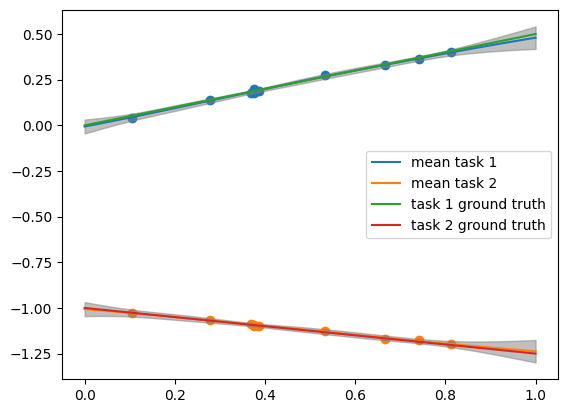

In [7]:
#mean and standard deviation
mean = my_gp2.posterior_mean(x_pred=x_pred1d.reshape(50,1))["m(x)"]
std = np.sqrt(my_gp2.posterior_covariance(x_pred=x_pred1d.reshape(50,1), x_out=np.array([0,1]))["v(x)"])


plt.plot(x_pred1d.reshape(50,1),mean[:,0], label = "mean task 1")
plt.plot(x_pred1d.reshape(50,1),mean[:,1], label = "mean task 2")
plt.scatter(x_data,y_data1) 
plt.scatter(x_data,y_data2) 
plt.plot(x_pred1d,f1(x_pred1d), label = "task 1 ground truth")
plt.plot(x_pred1d,f2(x_pred1d), label = "task 2 ground truth")
plt.fill_between(x_pred1d, mean[:,0] - 3. * std[:,0], mean[:,0] + 3. * std[:,0], alpha = 0.5, color = "grey")
plt.fill_between(x_pred1d, mean[:,1] - 3. * std[:,1], mean[:,1] + 3. * std[:,1], alpha = 0.5, color = "grey")
plt.legend()
plt.show()

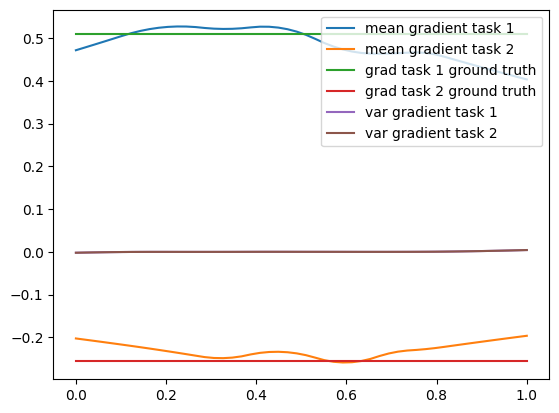

In [8]:
#mean gradient and variance gradient
mean_grad = my_gp2.posterior_mean_grad(x_pred=x_pred1d.reshape(50,1), x_out=np.array([0,1]))["dm/dx"]
var_grad = my_gp2.posterior_covariance_grad(x_pred=x_pred1d.reshape(50,1), x_out=np.array([0,1]))["dv/dx"]

plt.plot(x_pred1d.reshape(50,1),mean_grad[:,0,0], label = "mean gradient task 1")
plt.plot(x_pred1d.reshape(50,1),mean_grad[:,0,1], label = "mean gradient task 2")
plt.plot(x_pred1d,np.gradient(f1(x_pred1d), 1./50.), label = "grad task 1 ground truth")
plt.plot(x_pred1d,np.gradient(f2(x_pred1d), 1./50.), label = "grad task 2 ground truth")
plt.plot(x_pred1d.reshape(50,1),var_grad[:,0,0], label = "var gradient task 1")
plt.plot(x_pred1d.reshape(50,1),var_grad[:,0,1], label = "var gradient task 2")
plt.legend()
plt.show()

### ask()ing for new measurements
For a multi-task GP the acquisition functions score all outputs at once (`x_out`, all by default):
`variance` sums the variances over the outputs, `ucb`, `expected improvement`, `knowledge gradient`
and `noisy expected improvement` act on the sum of the outputs.

In [9]:
print("asking for the best 2 candidates out of 3:")
print(my_gp2.ask([np.array([0.0]), np.array([0.2]), np.array([1.])], n=2))

print("asking for the best new suggestion across the space [0,1], vectorized=True (default):")
print(my_gp2.ask(np.array([[0.,1.]]), n=1))

print("asking for the best new suggestion across the space [0,1], without vectorization:")
print(my_gp2.ask(np.array([[0.,1.]]), n=1, vectorized = False))

print("asking for the best new 4 suggestions across the space [0,1] with total correlation:")
print(my_gp2.ask(np.array([[0.,1.]]), n=4, vectorized = False, acquisition_function="total correlation"))

print("asking for an optimized result")
print(my_gp2.ask(np.array([[0.,1.]]), n=30, method = "hgdl", max_iter=100, dask_client=client))

asking for the best 2 candidates out of 3:
{'x': array([[1.],
       [0.]]), 'f_a(x)': array([0.00084012, 0.0003248 ]), 'opt_obj': None}
asking for the best new suggestion across the space [0,1], vectorized=True (default):
{'x': array([[0.99999421]]), 'f_a(x)': array([0.00084008]), 'opt_obj': None}
asking for the best new suggestion across the space [0,1], without vectorization:
{'x': array([[0.99999988]]), 'f_a(x)': array([0.00084012]), 'opt_obj': None}
asking for the best new 4 suggestions across the space [0,1] with total correlation:


/home/marcus/Coding/gpCAM/gpcam/surrogate_model.py:109: UserWarning:

ask() is returning the 2 individually best candidates under `variance`, which scores one point at a time. They are not mutually optimal and are often near-duplicates, since nothing stops the top scorers from sitting on top of each other. For a batch chosen to be jointly informative use ['relative information entropy', 'total correlation'], which score a whole set.

/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:596: UserWarning:

I set vectorized=False for total corr. or rel. inf. entropy.



{'x': array([[0.02420859],
       [0.16415493],
       [0.88137066],
       [0.98998487]]), 'f_a(x)': array([-42.21428262]), 'opt_obj': None}
asking for an optimized result
{'x': array([[1.        ],
       [0.        ],
       [0.13037559],
       [0.139081  ],
       [0.81111252],
       [0.58683514],
       [0.56983383],
       [0.7778879 ],
       [0.51934053],
       [0.65918618],
       [0.69584278],
       [0.72487149],
       [0.37488959]]), 'f_a(x)': array([8.40124403e-04, 3.24802331e-04, 6.48394303e-05, 6.16863446e-05,
       6.04854735e-05, 4.19048763e-05, 4.15935376e-05, 4.00196177e-05,
       3.83823093e-05, 3.66017882e-05, 3.31750549e-05, 3.18533459e-05,
       1.76219210e-05]), 'opt_obj': <hgdl.hgdl.HGDL object at 0x7f74e199b090>}


/home/marcus/Coding/gpCAM/gpcam/surrogate_model.py:179: UserWarning:

An insufficient number of unique optima identified. Try `total correlation` or the use of candidates by providing them as a list to ask(). 



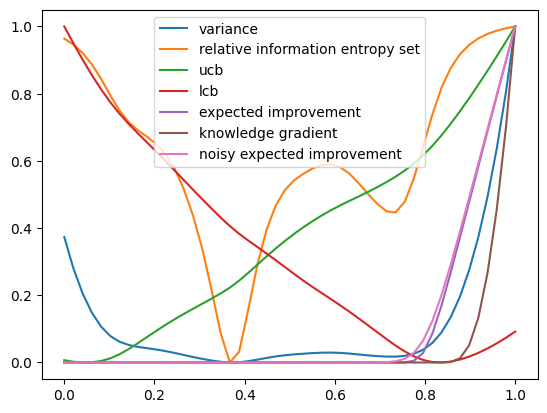

relative information entropy [0.99983033 0.99982328]
total correlation [9.99588890e-01 2.66121945e-04]


In [10]:
acquisition_functions = ["variance", "relative information entropy set", "ucb", "lcb", "expected improvement",
                         "knowledge gradient", "noisy expected improvement"]
for acq_func in acquisition_functions:
    res = my_gp2.evaluate_acquisition_function(x_pred1d.reshape(-1,1), acquisition_function=acq_func)
    plt.plot(x_pred1d, (res - np.min(res)) / (np.max(res) - np.min(res)), label = acq_func)
plt.legend()
plt.show()

#the set-valued ones, and one output only (x_out holds the task coordinates in the Cartesian mode)
for acq_func in ["relative information entropy", "total correlation"]:
    print(acq_func, my_gp2.ask(np.array([[0.,1.]]), n = 2, acquisition_function = acq_func, x_out = np.array([0.]))["x"].ravel())

### What if some tasks are missing from the data

#### It works just fine, but we have to insert np.nan at positions of missing data, both for y and the variances. 

In [11]:
y_data = np.column_stack([y_data1, y_data2])
noise_variances = np.zeros(y_data.shape) + 0.01
y_data[2,0] = np.nan
noise_variances[2,0] = np.nan

y_data[6,1] = np.nan
noise_variances[6,1] = np.nan

my_gp2 = GPOptimizer(x_data.reshape(len(x_data),1), y_data, noise_variances=noise_variances, multi_task_mode = "cartesian")
print("Local training in progress")
my_gp2.train(max_iter = 20)

Local training in progress


/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:730: UserWarning:

Hyperparameters initialized to a vector of ones.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1350: UserWarning:

Default hyperparameter_bounds initialized because none were provided. This will fail for custom kernel, mean, or noise functions



array([0.00462245, 0.30384581, 0.02165209])

## 3d Example

### Data

In [12]:
data = np.load("./data/sim_variable_mod.npy")
sparsification = 4

x_data3 = data[:,5:][::sparsification]
y_data3 = data[:,0:2][::sparsification]

#it is good practice to check the format of the data
print(x_data3.shape)
print(y_data3.shape)

(1583, 3)
(1583, 2)


In [13]:
index = np.where(x_data3[:,2] == 1200.)[0]
x_data3=x_data3[index,0:2]
y_data3=y_data3[index]

for i in range(x_data3.shape[1]):
    x_data3[:,i] = x_data3[:,i] - np.min(x_data3[:,i])
    x_data3[:,i] = x_data3[:,i] / np.max(x_data3[:,i])

In [14]:
x = np.linspace(0,1,100)
y = np.linspace(0,1,100)
x_pred3D = np.asarray(list(product(x, y)))

In [15]:
def scatter(x,y,z,size=3, color = 1):
    #if not color: color = z
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(x=x, y=y, z=z,mode='markers',marker=dict(color=color, size = size)))
    
    
    fig.update_layout(autosize=False,
                  width=800, height=800,
                  font=dict(size=18,),
                  margin=dict(l=0, r=0, b=0, t=0))
    fig.show()

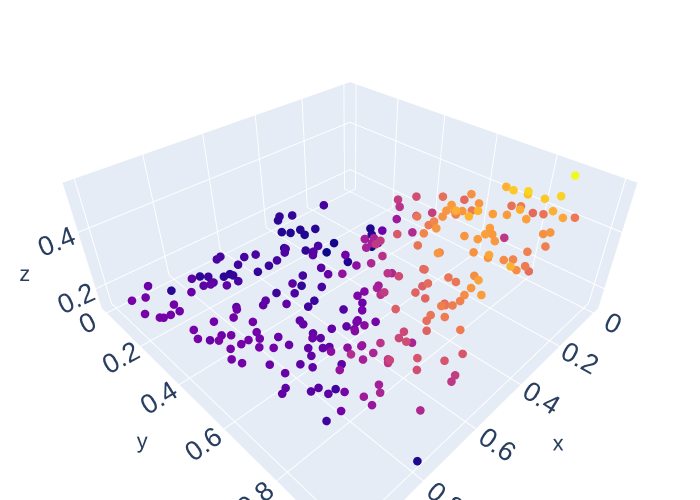

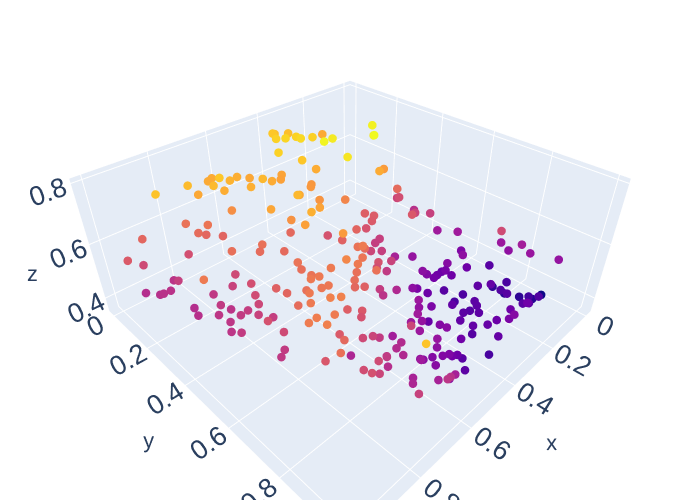

In [16]:
scatter(x_data3[:,0],x_data3[:,1],y_data3[:,0], size = 5, color = y_data3[:,0])
scatter(x_data3[:,0],x_data3[:,1],y_data3[:,1], size = 5, color = y_data3[:,1])

### Initialization

#### (a) Default behavior --- minimal

In [17]:
my_gp2 = GPOptimizer(x_data3,y_data3, multi_task_mode = "cartesian")
print("Local training in progress")
my_gp2.train(max_iter = 2)

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:730: UserWarning:

Hyperparameters initialized to a vector of ones.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:766: UserWarning:

No noise function or measurement noise provided. Noise variances will be set to (0.01 * mean(|y_data|))^2.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1350: UserWarning:

Default hyperparameter_bounds initialized because none were provided. This will fail for custom kernel, mean, or noise functions



Local training in progress


array([0.16021043, 0.34307626, 0.22821335, 0.01      ])

#### (b) Custom kernel
It is vital in the multi-task case to think hard about kernel design. The kernel is now a function
over X x X x T x T, where X is the input and T is the output space. Print the input of the kernel, it will have the dimensionality of this cartesian product space. 
The default kernel is just a Matern kernel operating in this new space.

In [18]:
#A simple kernel that won't lead to good performance because it's stationary
from gpcam.kernels import *
def mkernel(x1,x2,hps):
    d = get_distance_matrix(x1,x2)
    return hps[0] * matern_kernel_diff1(d,hps[1])

In [19]:
my_gp2 = GPOptimizer(x_data3,y_data3,
            init_hyperparameters=np.ones((2)), kernel_function=mkernel, multi_task_mode = "cartesian"
           )
print("Local training in progress")


bounds = np.array([[0.01,1.],[0.01,1.]])
my_gp2.train(hyperparameter_bounds=bounds,max_iter = 20)

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:766: UserWarning:

No noise function or measurement noise provided. Noise variances will be set to (0.01 * mean(|y_data|))^2.



Local training in progress


array([0.01      , 0.10002064])

#### (c) A custom deep kernel

In [20]:
from gpcam.deep_kernel_network import *
from gpcam.kernels import *
iset_dim = 3
gp_deep_kernel_layer_width = 5
n = Network(iset_dim, gp_deep_kernel_layer_width)
print(n.number_of_hps)

def deep_multi_task_kernel(x1, x2, hps):  # pragma: no cover
    signal_var = hps[0]
    length_scale = hps[1]
    hps_nn = hps[2:]
    w1_indices = np.arange(0, gp_deep_kernel_layer_width * iset_dim)
    last = gp_deep_kernel_layer_width * iset_dim
    w2_indices = np.arange(last, last + gp_deep_kernel_layer_width ** 2)
    last = last + gp_deep_kernel_layer_width ** 2
    w3_indices = np.arange(last, last + gp_deep_kernel_layer_width * iset_dim)
    last = last + gp_deep_kernel_layer_width * iset_dim
    b1_indices = np.arange(last, last + gp_deep_kernel_layer_width)
    last = last + gp_deep_kernel_layer_width
    b2_indices = np.arange(last, last + gp_deep_kernel_layer_width)
    last = last + gp_deep_kernel_layer_width
    b3_indices = np.arange(last, last + iset_dim)

    n.set_weights(hps_nn[w1_indices].reshape(gp_deep_kernel_layer_width, iset_dim),
                  hps_nn[w2_indices].reshape(gp_deep_kernel_layer_width, gp_deep_kernel_layer_width),
                  hps_nn[w3_indices].reshape(iset_dim, gp_deep_kernel_layer_width))
    n.set_biases(hps_nn[b1_indices].reshape(gp_deep_kernel_layer_width),
                 hps_nn[b2_indices].reshape(gp_deep_kernel_layer_width),
                 hps_nn[b3_indices].reshape(iset_dim))
    x1_nn = n.forward(x1)
    x2_nn = n.forward(x2)
    d = get_distance_matrix(x1_nn, x2_nn)
    k = signal_var * matern_kernel_diff1(d, length_scale)
    return k


my_gp2 = GPOptimizer(x_data3,y_data3,
            init_hyperparameters=np.ones((n.number_of_hps+2))*0.1, kernel_function=deep_multi_task_kernel,
            multi_task_mode = "cartesian"
           )

print("MCMC Training in progress")
bounds = np.zeros((n.number_of_hps+2,2))
bounds[0] = np.array([0.01,1.])
bounds[1] = np.array([0.1,1.])
bounds[2:] = np.array([-1,1])
my_gp2.train(hyperparameter_bounds=bounds,max_iter = 300, method = "mcmc", info = True)

68
MCMC Training in progress
Starting likelihood. f(x)=  -119799.77430417147


/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:766: UserWarning:

No noise function or measurement noise provided. Noise variances will be set to (0.01 * mean(|y_data|))^2.



Finished  10  out of  300  iterations. f(x)=  -29418.487038127678
Finished  20  out of  300  iterations. f(x)=  -15391.168910606073
Finished  30  out of  300  iterations. f(x)=  -8990.469270040949
Finished  40  out of  300  iterations. f(x)=  -3801.3902955637664
Finished  50  out of  300  iterations. f(x)=  -1552.880585568055
Finished  60  out of  300  iterations. f(x)=  -46.202064635098566
Finished  70  out of  300  iterations. f(x)=  754.2215999942193
Finished  80  out of  300  iterations. f(x)=  754.2215999942193
Finished  90  out of  300  iterations. f(x)=  828.8958391911599
Finished  100  out of  300  iterations. f(x)=  854.8059452771643
Finished  110  out of  300  iterations. f(x)=  875.5754119984495
Finished  120  out of  300  iterations. f(x)=  875.5754119984495
Finished  130  out of  300  iterations. f(x)=  875.5754119984495
Finished  140  out of  300  iterations. f(x)=  874.4760688375957
Finished  150  out of  300  iterations. f(x)=  874.4760688375957
Finished  160  out of  3

array([ 0.14086975,  0.10214796,  0.45643829, -0.08122387,  0.27539156,
        0.11642269, -0.40382483,  0.14730226,  0.3155965 ,  0.83686837,
       -0.1143235 ,  0.27348606,  0.33373023, -0.30542197,  0.01107652,
       -0.33160744,  0.76478309, -0.39951969, -0.47869948,  0.74086987,
        0.01341668,  0.14687865,  0.28560848,  0.72319826, -0.03068242,
        0.64184706,  0.1368641 ,  0.01691696,  0.04790795,  0.29942017,
        0.26746343,  0.50749043,  0.28199808, -0.02586257,  0.24167975,
        0.14827242,  0.68308999,  0.63167605,  0.82645538, -0.09075812,
        0.04392358,  0.36472818,  0.25688765,  0.51947247, -0.12766355,
       -0.05010382, -0.11634875,  0.25773868,  0.64864921,  0.04956088,
       -0.05831247, -0.19167727,  0.01686876,  0.39246547, -0.31782161,
        0.72914351,  0.23786193,  0.23273443,  0.09021383, -0.03762911,
        0.59532608,  0.86819802,  0.00431153, -0.05597388,  0.42049127,
       -0.2802241 ,  0.11905473,  0.15944134,  0.1713597 ,  0.06

### Prediction

In [21]:
mean = my_gp2.posterior_mean(x_pred3D)["m(x)"]
var =  my_gp2.posterior_covariance(x_pred3D)["v(x)"]

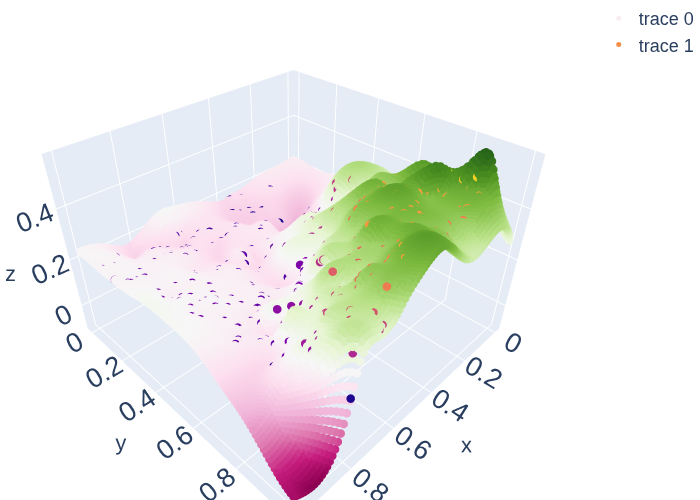

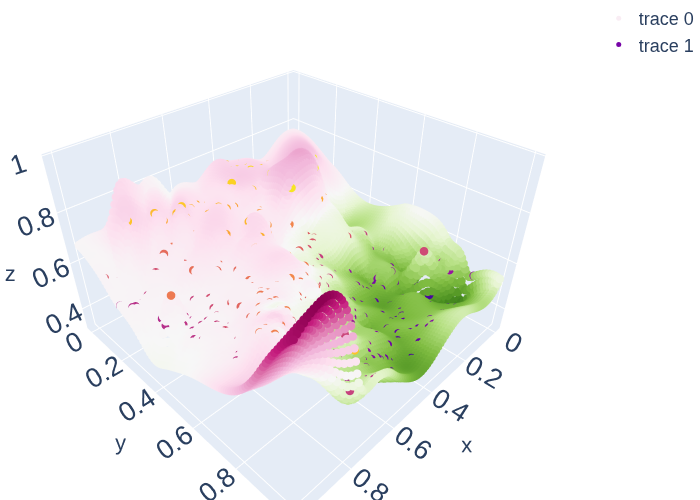

In [22]:
fig = go.Figure()
fig.add_trace(go.Scatter3d(x=x_pred3D[:,0],y=x_pred3D[:,1], z=mean[:,0],
                             mode='markers',marker=dict(color=mean[:,0], size = 5)))
fig.add_trace(go.Scatter3d(x=x_data3[:,0], y=x_data3[:,1] , z=y_data3[:,0],
                           mode='markers',marker=dict(color=y_data3[:,0], size = 5)))
fig.update_layout(autosize=False,
                  width=800, height=800,
                  font=dict(size=18,),
                  margin=dict(l=0, r=0, b=0, t=0))
fig.show()



fig = go.Figure()
fig.add_trace(go.Scatter3d(x=x_pred3D[:,0],y=x_pred3D[:,1], z=mean[:,1],
                             mode='markers',marker=dict(color=mean[:,0], size = 5)))
fig.add_trace(go.Scatter3d(x=x_data3[:,0], y=x_data3[:,1] , z=y_data3[:,1],
                           mode='markers',marker=dict(color=y_data3[:,1], size = 5)))
fig.update_layout(autosize=False,
                  width=800, height=800,
                  font=dict(size=18,),
                  margin=dict(l=0, r=0, b=0, t=0))
fig.show()

In [23]:
print("n=1")
my_gp2.ask(np.array([[0,1],[0,1]]), n = 1, max_iter=2,pop_size=2, info = True,
           acquisition_function = 'relative information entropy set', x_out = np.array([0.,1.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 1, max_iter=2,pop_size=2, info = True,
           acquisition_function = 'relative information entropy', x_out = np.array([0.,1.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 1, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'variance', x_out = np.array([0.,1.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 1, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'total correlation', x_out = np.array([0.,1.]), vectorized = True)

print("n>1")
my_gp2.ask(np.array([[0,1],[0,1]]), n = 4, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'relative information entropy set', x_out = np.array([0.,1.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 5, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'relative information entropy', x_out = np.array([0.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 3, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'variance', x_out = np.array([0.,1.]), vectorized = True)
my_gp2.ask(np.array([[0,1],[0,1]]), n = 2, max_iter=2,pop_size=2,info = True,
           acquisition_function = 'total correlation', vectorized = True)

n=1
differential_evolution step 1: f(x)= 18.62107002581208
differential_evolution step 2: f(x)= 18.62107002581208
differential_evolution step 1: f(x)= 4.566667115574945
differential_evolution step 2: f(x)= 1.417586888178569
differential_evolution step 1: f(x)= -0.062385586914617694
differential_evolution step 2: f(x)= -0.062385586914617694


/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:596: UserWarning:

I set vectorized=False for total corr. or rel. inf. entropy.



differential_evolution step 1: f(x)= 4.643527690147266
differential_evolution step 2: f(x)= 4.627970897651494
n>1


/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:592: UserWarning:

You specified n>1 and method != 'hgdl' in ask(). The acquisition function has therefore been changed to 'total correlation'.



differential_evolution step 1: f(x)= 12.431222499076114
differential_evolution step 2: f(x)= 12.431222499076114
differential_evolution step 1: f(x)= 162.77388862628104
differential_evolution step 2: f(x)= 162.77388862628104
differential_evolution step 1: f(x)= 9.306493535388768
differential_evolution step 2: f(x)= 6.986299081402308
differential_evolution step 1: f(x)= 6.63593454815441
differential_evolution step 2: f(x)= 5.988490119945936


{'x': array([[0.20724432, 0.12945319],
        [0.87484759, 0.98592221]]),
 'f_a(x)': array([-5.98849012]),
 'opt_obj': None}

## Three multi-task modes
Everything above used `multi_task_mode="cartesian"`: every (input, task) pair becomes one point of a single-task GP over the combined input-output space. That allows any kernel and missing tasks, at the cost of a GP over (number of inputs) x (number of tasks) points. Two other modes cover common special cases much more cheaply:

* `multi_task_mode="independent"` (the default for a `y_data` with several columns) -- several GPs that share kernel, noise and hyperparameters but are otherwise unrelated. The tasks are right-hand sides of one GP over the inputs, so only one covariance matrix over the inputs is factored.
* `multi_task_mode="kronecker"` -- every task observed at every input, with a separable kernel $K = K_x \otimes F_1 \otimes \dots$. K is never formed, which makes millions of (input, output) pairs tractable.

In both, `y_data` is given as before, (inputs x tasks), but must not contain NaN; the noise is one variance per input; and `x_out` in the posterior selects tasks by index.

### Several GPs at once (independent)
Six tasks -- sine waves with different phases -- learned with one set of hyperparameters. The default prior mean is each task's own average.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:730: UserWarning:

Hyperparameters initialized to a vector of ones.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1350: UserWarning:

Default hyperparameter_bounds initialized because none were provided. This will fail for custom kernel, mean, or noise functions



shared hyperparameters: [1.34624861 0.62954657]
selected tasks: (50, 2)


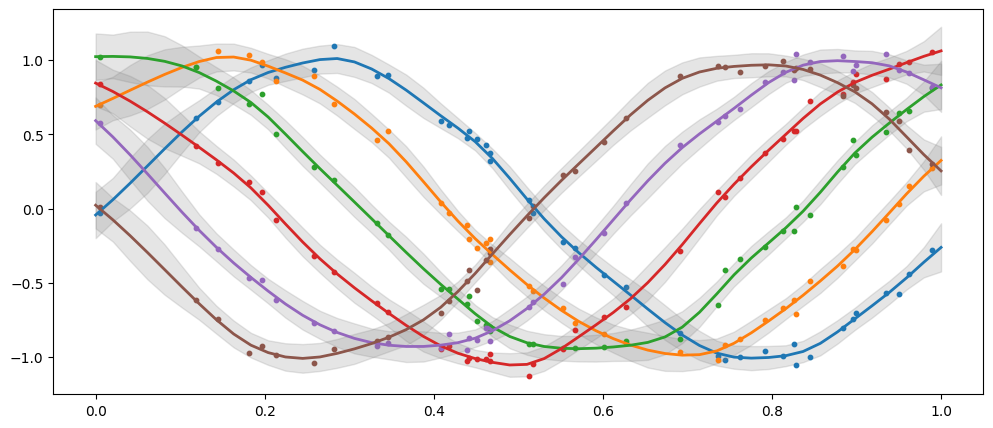

In [24]:
x_many = np.random.rand(40).reshape(-1, 1)
phases = np.linspace(0, np.pi, 6)
y_many = np.sin(6. * x_many + phases[None, :]) + np.random.normal(0, 0.05, (40, 6))

gp_many = GPOptimizer(x_many, y_many, noise_variances=np.full(40, 0.0025), multi_task_mode="independent")
gp_many.train(max_iter = 50)
print("shared hyperparameters:", gp_many.hyperparameters)

mean = gp_many.posterior_mean(x_pred1d.reshape(-1, 1))["m(x)"]           #(50, 6): one column per task
sd = np.sqrt(gp_many.posterior_covariance(x_pred1d.reshape(-1, 1))["v(x)"])
print("selected tasks:", gp_many.posterior_mean(x_pred1d.reshape(-1, 1), x_out=np.array([0, 5]))["m(x)"].shape)

plt.figure(figsize = (12,5))
for i in range(6):
    plt.plot(x_pred1d, mean[:, i], linewidth = 2)
    plt.fill_between(x_pred1d, mean[:, i] - 3. * sd[:, i], mean[:, i] + 3. * sd[:, i], alpha = 0.2, color = "grey")
    plt.scatter(x_many[:, 0], y_many[:, i], s = 10)
plt.show()

In [25]:
#ask() works the same in every mode; here for task 5 only (x_out holds task indices here)
print(gp_many.ask(np.array([[0.,1.]]), acquisition_function = "ucb")["x"])
print(gp_many.ask(np.array([[0.,1.]]), acquisition_function = "ucb", x_out = np.array([5]))["x"])

[[2.41940421e-06]]
[[0.78495756]]


### Kronecker structure
#### (a) The default: learning how the tasks are correlated
Without a kernel, Kronecker mode uses the coregionalization kernel `gpcam.kernels.CoregionalizationKernel`: a Matern kernel over the inputs times a learned covariance between the tasks, $B = W W^T + \mathrm{diag}(\kappa)$. Its hyperparameters are `[length scales, W, kappa]`, with defaults and bounds taken from the data. On the two linear tasks of the 1d example it should find that they are perfectly anti-correlated: one rises where the other falls.

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1350: UserWarning:

Default hyperparameter_bounds initialized because none were provided. This will fail for custom kernel, mean, or noise functions



hyperparameters [length scale, W, kappa]: [ 2.14166117e+00 -3.32577941e-01  1.60487560e-01  1.10608087e-05
  2.59180353e-06]
learned task correlation:
[[ 1.        -0.9998997]
 [-0.9998997  1.       ]]


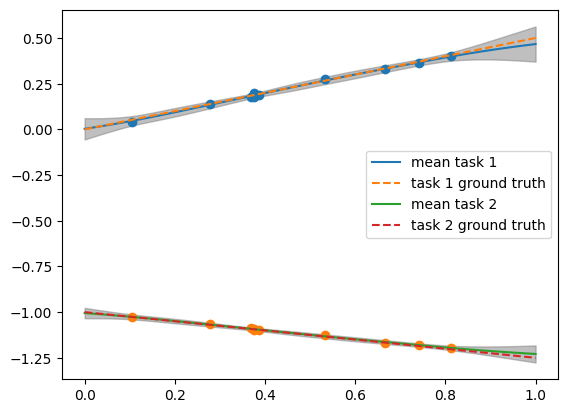

In [26]:
gp_kron = GPOptimizer(x_data.reshape(-1, 1), np.column_stack([y_data1, y_data2]), noise_variances=np.full(len(x_data), 1e-4),
             multi_task_mode="kronecker")
gp_kron.train()
print("hyperparameters [length scale, W, kappa]:", gp_kron.hyperparameters)
B = gp_kron.K[1]   #in Kronecker mode K is the list of factors [K_x, B]
print("learned task correlation:")
print(B / np.sqrt(np.outer(np.diag(B), np.diag(B))))

mean = gp_kron.posterior_mean(x_pred1d.reshape(-1, 1))["m(x)"]
sd = np.sqrt(gp_kron.posterior_covariance(x_pred1d.reshape(-1, 1))["v(x)"])
for i, f in enumerate((f1, f2)):
    plt.plot(x_pred1d, mean[:, i], label = f"mean task {i + 1}")
    plt.fill_between(x_pred1d, mean[:, i] - 3. * sd[:, i], mean[:, i] + 3. * sd[:, i], alpha = 0.5, color = "grey")
    plt.plot(x_pred1d, f(x_pred1d), "--", label = f"task {i + 1} ground truth")
plt.scatter(x_data, y_data1)
plt.scatter(x_data, y_data2)
plt.legend()
plt.show()

In [27]:
#Kronecker mode has no total correlation, so ask(n > 1) uses relative information entropy instead
print(gp_kron.ask(np.array([[0.,1.]]), acquisition_function = "expected improvement")["x"])
print(gp_kron.ask(np.array([[0.,1.]]), n = 3)["x"].ravel())

[[0.99999574]]


/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:592: UserWarning:

You specified n>1 and method != 'hgdl' in ask(). The acquisition function has therefore been changed to 'relative information entropy'.

/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:596: UserWarning:

I set vectorized=False for total corr. or rel. inf. entropy.



[0.99684779 0.99374162 0.99504749]


#### (b) Images as outputs
Each input -- one parameter -- produces a 30 x 30 image: a blob that moves down the image as the parameter grows. That is 900 tasks, and with 40 inputs 36 000 (input, pixel) pairs; the Cartesian mode would need a 36 000 x 36 000 covariance matrix (10 GB).

In Kronecker mode the kernel returns its factors as a list. Here it splits the 900 pixels into image rows x image columns, `[K_x, K_rows, K_cols]`, so that every factor is small: 40 x 40, 30 x 30 and 30 x 30. The flattened pixel index is row-major, as in `np.kron(K_rows, K_cols)`.

36000 (input, pixel) pairs, trained in 0.28 s: [0.01195057 0.24637429 0.15048035 0.20439983]


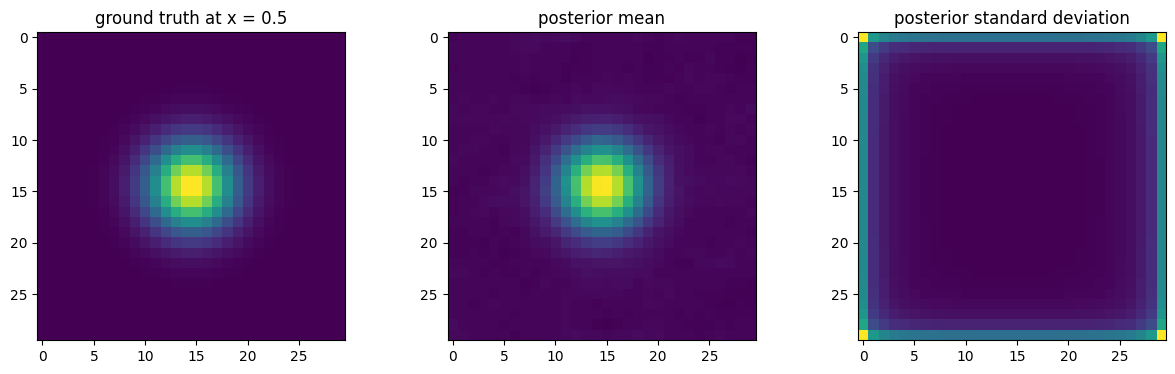

In [28]:
import time
side = 30
pixels = np.linspace(0, 1, side)
rows, cols = np.meshgrid(pixels, pixels, indexing = "ij")
def image(x): return np.exp(-((rows - 0.2 - 0.6 * x) ** 2 + (cols - 0.5) ** 2) / 0.02)

x_img = np.random.rand(40).reshape(-1, 1)
y_img = np.array([image(x).ravel() for x in x_img[:, 0]]) + np.random.normal(0, 0.02, (40, side * side))

def image_kernel(x1, x2, hps):
    K_x = hps[0] * np.exp(-(x1[:, :1] - x2[:, :1].T) ** 2 / hps[1] ** 2)
    K_rows = np.exp(-np.subtract.outer(pixels, pixels) ** 2 / hps[2] ** 2)
    K_cols = np.exp(-np.subtract.outer(pixels, pixels) ** 2 / hps[3] ** 2)
    return [K_x, K_rows, K_cols]

st = time.time()
gp_img = GPOptimizer(x_img, y_img, init_hyperparameters = np.array([0.1, 0.2, 0.1, 0.1]), noise_variances = np.full(40, 4e-4),
            kernel_function = image_kernel, multi_task_mode = "kronecker")
gp_img.train(hyperparameter_bounds = np.array([[0.001, 10.], [0.01, 2.], [0.01, 1.], [0.01, 1.]]))
print(y_img.size, "(input, pixel) pairs, trained in", round(time.time() - st, 2), "s:", gp_img.hyperparameters)

x_new = np.array([[0.5]])
prediction = gp_img.posterior_mean(x_new)["m(x)"].reshape(side, side)
sd = np.sqrt(gp_img.posterior_covariance(x_new, variance_only = True)["v(x)"]).reshape(side, side)
fig, axes = plt.subplots(1, 3, figsize = (15, 4))
for ax, img, title in zip(axes, (image(0.5), prediction, sd), ("ground truth at x = 0.5", "posterior mean", "posterior standard deviation")):
    ax.imshow(img)
    ax.set_title(title)
plt.show()

In [32]:
# Where would an image be most uncertain? The variance summed over all 900 pixels
print(gp_img.ask(np.array([[0.,1.]]), acquisition_function = "variance")["x"])

[[3.28878377e-05]]
